# 02 · "Study next" recommender (logistic regression, trained on real OULAD data)

**In the app:** Home shows a *Needs attention* suggestion with a **Why?** explanation, and **Log session** / **Focus timer** pre-select that subject.

**Data:** the real OULAD learners who took **2–3 modules in the same semester** (built in notebook 00). Each module plays the
role of a Milestone subject.

**Label:** did the learner study module *s* on day *t*? **Features** (computed only from days before *t*):

| feature | definition | unit-free? |
|---|---|---|
| `log_days_since` | log(1 + days since the subject was last studied), capped at 30 | ✓ |
| `goal_left` | share of this week's target not yet reached (0–1) | ✓ |
| `weekday_affinity` | share of the last 8 same weekdays on which the subject was studied | ✓ |
| `share_14d` | the subject's share of all activity in the last 14 days | ✓ |
| `yesterday` | studied yesterday (0/1) | ✓ |

**Goal proxy (honest note):** OULAD has no weekly goals. During training, a subject's weekly target is the learner's **median
weekly activity on that module over the previous 4 weeks**, floored by the median of all their *earlier* non-zero weeks on it.
Only past weeks are used, so there is no look-ahead. In the app, the user's real goal is used.

In [1]:
import json, pathlib, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = pathlib.Path('data')
PROC = DATA / 'processed'
ASSETS = pathlib.Path('../app/src/main/assets/ml')
ASSETS.mkdir(parents=True, exist_ok=True)
RED, INK, GREY, LINE = '#E11D2A', '#111111', '#8C8C8C', '#DEDEDE'

def is_test(student_id):
    """Deterministic 20% hold-out split by student (no student appears in both sets)."""
    return int(hashlib.md5(str(student_id).encode()).hexdigest(), 16) % 5 == 0

In [2]:
mm = pd.read_parquet(PROC / 'daily_multimodule.parquet')
FEATURES = ['log_days_since', 'goal_left', 'weekday_affinity', 'share_14d', 'yesterday']

def learner_rows(lid, g):
    mods = sorted(g.code_module.unique())
    n_days = int(g.n_days.max())
    M = np.zeros((n_days, len(mods)))
    for j, m in enumerate(mods):
        gm = g[g.code_module == m]
        M[gm.date.to_numpy(), j] = gm.clicks.to_numpy()
    # each module is only "active" until that enrolment ends
    active_until = np.array([int(g[g.code_module == m].n_days.max()) for m in mods])
    S = M > 0
    weekly = np.add.reduceat(M, np.arange(0, n_days, 7), axis=0)
    last = np.full(len(mods), -1)
    out = []
    for t in range(n_days):
        if t >= 28:
            w = t // 7
            # Only weeks BEFORE w are used (no peeking at the future): recent median, floored by the
            # median of all earlier non-zero weeks of that module for this learner.
            past = weekly[:w]
            floor = np.array([np.median(c[c > 0]) if (c > 0).any() else 1.0 for c in past.T])
            target = np.maximum(np.median(past[max(0, w-4):], axis=0), np.maximum(floor, 1.0))
            done = M[w*7:t].sum(0)
            goal_left = np.clip((target - done) / target, 0, 1)
            ds = np.minimum(np.where(last < 0, 30, t - last), 30)
            aff = S[[t - 7*k for k in range(1, 9) if t - 7*k >= 0]].mean(0)
            tot = M[t-14:t].sum()
            share = M[t-14:t].sum(0) / tot if tot > 0 else np.zeros(len(mods))
            for j in range(len(mods)):
                if t < active_until[j]:
                    out.append((lid, t, j, np.log1p(ds[j]), goal_left[j], aff[j], share[j], float(S[t-1, j]), int(S[t, j])))
        last = np.where(S[t], t, last)
    return out

df = pd.DataFrame([r for lid, g in mm.groupby('learner_id') for r in learner_rows(lid, g)],
                  columns=['learner_id', 'day', 'subj'] + FEATURES + ['y'])
df = df.merge(mm[['learner_id', 'id_student']].drop_duplicates(), on='learner_id')
df['test'] = df.id_student.map(is_test)
train, test = df[~df.test], df[df.test]
print(f'{len(df):,} learner-subject-days | positive rate {df.y.mean():.3f} | '
      f'{df.learner_id.nunique():,} learners ({test.learner_id.nunique()} held out)')

173,443 learner-subject-days | positive rate 0.230 | 412 learners (81 held out)


In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, log_loss

clf = LogisticRegression(C=1.0, max_iter=2000).fit(train[FEATURES], train.y)
p = clf.predict_proba(test[FEATURES])[:, 1]
print(f'held-out AUC {roc_auc_score(test.y, p):.3f} | log-loss {log_loss(test.y, p):.4f} '
      f'(constant-rate log-loss {log_loss(test.y, np.full(len(test), train.y.mean())):.4f})')
pd.Series(clf.coef_[0], index=FEATURES).round(3).to_frame('weight')

held-out AUC 0.795 | log-loss 0.4407 (constant-rate log-loss 0.5514)


,weight
log_days_since,-0.663
goal_left,-0.468
weekday_affinity,1.963
share_14d,-0.062
yesterday,0.553


## Does the top suggestion match what the learner actually studied?
Only days where the learner studied at least one subject are counted. Baselines are simple rules a hand-written app might use.

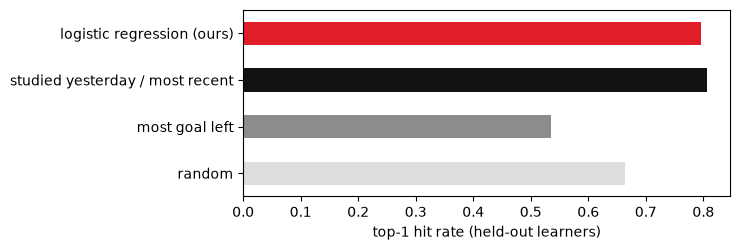

logistic regression (ours)         0.797
studied yesterday / most recent    0.806
most goal left                     0.535
random                             0.663
dtype: float64

In [4]:
def top1(frame, score):
    f = frame.assign(score=score)
    f = f[f.groupby(['learner_id', 'day']).y.transform('sum') > 0]
    f = f[f.groupby(['learner_id', 'day']).y.transform('size') > 1]   # a real choice exists
    pick = f.loc[f.groupby(['learner_id', 'day']).score.idxmax()]
    return pick.y.mean()

scores = {
    'logistic regression (ours)': p,
    'studied yesterday / most recent': -test.log_days_since.to_numpy() + 1e-3 * test.share_14d.to_numpy(),
    'most goal left': test.goal_left.to_numpy(),
    'random': np.random.default_rng(0).random(len(test)),
}
hits = pd.Series({k: top1(test, v) for k, v in scores.items()})
ax = hits.iloc[::-1].plot(kind='barh', color=[LINE, GREY, INK, RED], figsize=(7.5, 2.6))
ax.set_xlabel('top-1 hit rate (held-out learners)'); plt.tight_layout(); plt.show()
hits.round(3)

### Reading this honestly
As a *"guess what they'll study"* ranker, the model does **not** beat the trivial "same as yesterday" rule. Learners are
creatures of habit, and the recency rule already captures most of that. A suggestion that just repeats yesterday is also
useless advice.

So the app does **not** use the model as a ranker. It uses the model's **probability** as a measure of *how likely the
student is to get to this subject on their own today*, and suggests the subject they're **most likely to neglect** while its
weekly goal is unmet:

$$\text{need}(s) = \text{goal\_left}(s)\times\big(1 - P(\text{study } s\text{ today})\big)$$

That only works if the probabilities are **calibrated**, i.e. "30%" really means 30%. We check that next.

What we can and can't claim: calibration is measured **on OULAD learners** (activity in clicks, positive rate ~23%), not on
Milestone users. The decision rule itself can't be scored offline, because there is no ground truth for which subject a student
*should* have studied. It is a transparent product rule built on a calibrated estimate, not a validated recommender.

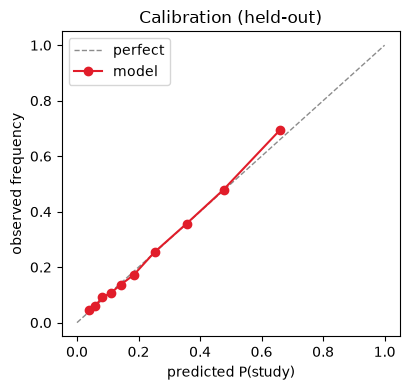

expected calibration error ≈ 0.007


In [5]:
from sklearn.calibration import calibration_curve
frac_pos, mean_pred = calibration_curve(test.y, p, n_bins=10, strategy='quantile')
fig, ax = plt.subplots(figsize=(4.2, 4))
ax.plot([0, 1], [0, 1], ls='--', color=GREY, lw=1, label='perfect')
ax.plot(mean_pred, frac_pos, marker='o', color=RED, label='model')
ax.set_xlabel('predicted P(study)'); ax.set_ylabel('observed frequency'); ax.legend(); ax.set_title('Calibration (held-out)')
plt.tight_layout(); plt.show()
ECE = float(np.average(np.abs(frac_pos - mean_pred)))
print(f'expected calibration error ≈ {ECE:.3f}')

## On-device personalisation: SGD with an L2 pull towards the prior
This is the exact algorithm in `SubjectRecommender.kt`. Each held-out learner's first 8 weeks of history are used for
personalisation, and their later days for testing. Hyper-parameters are chosen on **training** learners only.

In [6]:
W0 = np.r_[clf.intercept_, clf.coef_[0]]

def sgd(X, y, w0, lr, epochs, l2):
    w = w0.copy(); Xb = np.c_[np.ones(len(X)), X]
    for _ in range(epochs):
        for xi, yi in zip(Xb, y):
            w -= lr * ((1 / (1 + np.exp(-xi @ w)) - yi) * xi + l2 * (w - w0))
    return w

def personal(frame, lr, epochs, l2, split_day=28 + 56, max_learners=250):
    a, b = [], []
    for _, g in list(frame.groupby('learner_id'))[:max_learners]:
        tr, te = g[g.day < split_day], g[g.day >= split_day]
        if len(te) == 0 or te.y.nunique() < 2: continue
        w = sgd(tr[FEATURES].to_numpy(), tr.y.to_numpy(), W0, lr, epochs, l2)
        Xt = np.c_[np.ones(len(te)), te[FEATURES].to_numpy()]
        a.append(log_loss(te.y, 1 / (1 + np.exp(-Xt @ W0)), labels=[0, 1]))
        b.append(log_loss(te.y, 1 / (1 + np.exp(-Xt @ w)), labels=[0, 1]))
    return np.mean(a), np.mean(b)

grid = [(lr, ep, l2) for lr in [0.005, 0.02] for ep in [1, 3] for l2 in [0.01, 0.1]]
tuned = {g: personal(train, *g, max_learners=120)[1] for g in grid}
BEST = min(tuned, key=tuned.get)
prior_ll, pers_ll = personal(test, *BEST)
print('chosen (lr, epochs, l2) =', BEST)
print(f'held-out log-loss: global prior {prior_ll:.4f} -> personalised {pers_ll:.4f} '
      f'({(prior_ll - pers_ll) / prior_ll:+.1%})')

chosen (lr, epochs, l2) = (0.005, 1, 0.01)
held-out log-loss: global prior 0.4230 -> personalised 0.4211 (+0.5%)


In [7]:
export = {
    'version': 2, 'source': 'OULAD multi-module learners (CC-BY 4.0), held-out by student',
    'features': FEATURES, 'intercept': float(clf.intercept_[0]),
    'weights': [float(x) for x in clf.coef_[0]],
    'sgd': {'lr': BEST[0], 'epochs': BEST[1], 'l2': BEST[2]},
    'min_history_days': 14,
    'test_auc': float(roc_auc_score(test.y, p)),
    'test_top1': {k: float(v) for k, v in hits.items()},
    'test_calibration_error': ECE,
    'decision_rule': 'need = goal_left * (1 - p)',
}
(ASSETS / 'next_subject.json').write_text(json.dumps(export, indent=2))
export

{'version': 2,
 'source': 'OULAD multi-module learners (CC-BY 4.0), held-out by student',
 'features': ['log_days_since',
  'goal_left',
  'weekday_affinity',
  'share_14d',
  'yesterday'],
 'intercept': -0.5478976501315455,
 'weights': [-0.6633811984374299,
  -0.46794508766364445,
  1.9626120856822094,
  -0.06154840085337632,
  0.5530871675944006],
 'sgd': {'lr': 0.005, 'epochs': 1, 'l2': 0.01},
 'min_history_days': 14,
 'test_auc': 0.7948396347162953,
 'test_top1': {'logistic regression (ours)': 0.7966906946264745,
  'studied yesterday / most recent': 0.8060288335517694,
  'most goal left': 0.5353866317169069,
  'random': 0.6631716906946264},
 'test_calibration_error': 0.007494795029280785,
 'decision_rule': 'need = goal_left * (1 - p)'}

## Limitations
* After cleaning, only **412** real learners took multiple modules at once (81 held out), and they have 2–3 "subjects", while app users may track 5–6.
  All features are per-subject and unit-free, so the model applies to any number of subjects, but there are fewer
  examples with many subjects.
* The weekly-target proxy is learnt from past behaviour, not set by the learner.